# Spring Temperature and Snowmelt in a River Basin (ERA5-Land)

This notebook studies how **spring air temperature** relates to the **timing and amount of snowmelt** in a
HydroSHEDS river basin, using daily ERA5-Land reanalysis (`ECMWF/ERA5_LAND/DAILY_AGGR`, ~11 km) in Google Earth Engine.

**What it does**
1. Selects the level-5 HydroSHEDS basin containing a chosen point.
2. Extracts basin-mean daily temperature, snowmelt, snow water equivalent (SWE), snowfall and precipitation.
3. Plots day-of-year curves for selected years against the long-term mean (as in the original Earth Engine charts).
4. Computes yearly snowmelt metrics (total melt, peak SWE, and the dates when 25/50/75% of the year's melt has occurred),
   their trends, and their relation to spring temperature.

> Ported from the original Earth Engine JavaScript (Code Editor) script.

## 1. Setup

Results of the Earth Engine step are saved to `outputs/snowmelt/` year by year, so after a kernel restart
**Restart & Run All** loads finished years from disk instead of recomputing them.

In [1]:
import os, io
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image
from scipy import stats


C:\Users\moham\anaconda3\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.7) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [2]:
ee.Authenticate(auth_mode="localhost")
ee.Initialize(project="add your GEE username")

## 2. Parameters

In [3]:
# --- Output folders ---
FIG_DIR, OUT_DIR = "figures/snowmelt", "outputs/snowmelt"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# --- Basin selection ---
# Any point inside the basin of interest (this replaces 'geometry' in the original script).
# Default: Colorado Rocky Mountains headwaters. Replace with your own point (longitude, latitude).
POINT = (-106.10, 39.55)
BASIN_LEVEL = 5          # HydroSHEDS level (higher = smaller basins)

START_YEAR, END_YEAR = 2001, 2023      # long-term context
HIGHLIGHT_YEARS = [2018, 2019, 2020]   # years shown individually (as in the original script)
TEMP_MONTHS = (3, 6)     # spring temperature window: March–June, as in the original script
SCALE = 10000            # reduction scale (m), as in the original script
FORCE_RECOMPUTE = False  # True = ignore saved results (e.g. after changing the basin)

BANDS = ["temperature_2m", "snowmelt_sum", "snow_depth_water_equivalent", "snowfall_sum", "total_precipitation_sum"]
YEAR_COLORS = plt.cm.tab10.colors

## 3. Basin

HydroSHEDS basin 7050585120 | area ≈ 67,919 km²


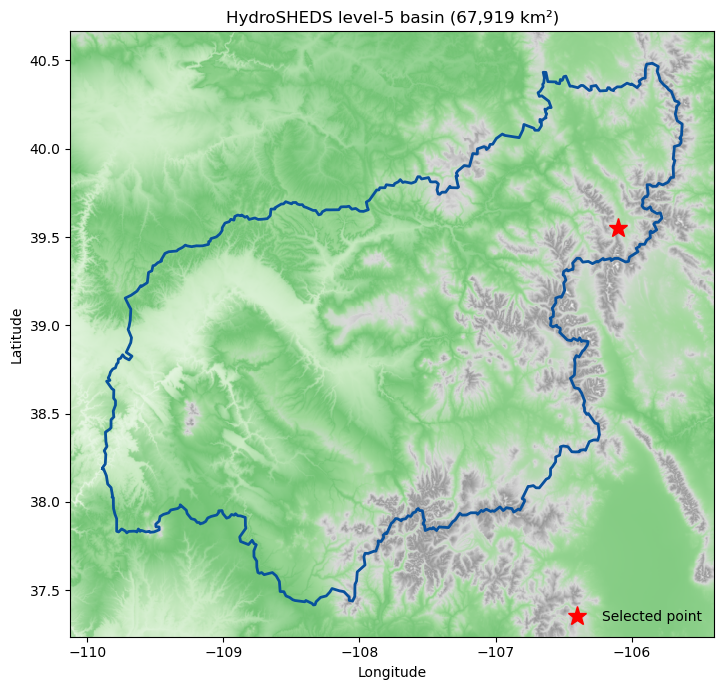

In [4]:
basins = (ee.FeatureCollection(f"WWF/HydroSHEDS/v1/Basins/hybas_{BASIN_LEVEL}")
            .filterBounds(ee.Geometry.Point(POINT))
            .map(lambda f: f.simplify(1000)))
roi = basins.geometry()

info = basins.first().getInfo()["properties"]
area_km2 = roi.area(100).divide(1e6).getInfo()
print(f"HydroSHEDS basin {info.get('HYBAS_ID')} | area ≈ {area_km2:,.0f} km²")

def draw_outline(ax, g, **kw):
    if g["type"] == "Polygon":
        ring = np.array(g["coordinates"][0]); ax.plot(ring[:, 0], ring[:, 1], **kw)
    elif g["type"] == "MultiPolygon":
        for poly in g["coordinates"]:
            ring = np.array(poly[0]); ax.plot(ring[:, 0], ring[:, 1], **kw)
    elif g["type"] == "GeometryCollection":
        for sub in g["geometries"]:
            draw_outline(ax, sub, **kw)

# Elevation background (static image so it renders on GitHub)
view = roi.bounds().buffer(20000).bounds()
dem = ee.Image("NASA/NASADEM_HGT/001").select("elevation")
url = dem.visualize(min=1000, max=4300, palette=["#f7fcf5", "#c7e9c0", "#74c476", "#a1d99b", "#d9d9d9", "#969696", "#ffffff"]
                    ).getThumbURL({"region": view, "dimensions": 1000, "crs": "EPSG:4326", "format": "png"})
dem_img = np.array(Image.open(io.BytesIO(requests.get(url, timeout=300).content)))
b = np.array(view.coordinates().getInfo()[0])
extent = [b[:, 0].min(), b[:, 0].max(), b[:, 1].min(), b[:, 1].max()]

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(dem_img, extent=extent)
draw_outline(ax, roi.getInfo(), color="#08519c", lw=2)
ax.plot(*POINT, "r*", ms=14, label="Selected point")
ax.set(xlabel="Longitude", ylabel="Latitude", title=f"HydroSHEDS level-{BASIN_LEVEL} basin ({area_km2:,.0f} km²)")
ax.set_aspect(1 / np.cos(np.deg2rad(POINT[1])))
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/01_basin_map.png"); plt.show()

## 4. Basin-mean daily ERA5-Land values

One request per year (about 365 images), saved to `daily_basin.csv` after each year.

In [5]:
DAILY_CSV = f"{OUT_DIR}/daily_basin.csv"
era5 = ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR").select(BANDS)

def basin_mean(img):
    vals = img.reduceRegion(reducer=ee.Reducer.mean(), geometry=roi, scale=SCALE, maxPixels=1e9)
    return ee.Feature(None, vals).set("date", img.date().format("YYYY-MM-dd"))

saved = pd.read_csv(DAILY_CSV) if os.path.exists(DAILY_CSV) and not FORCE_RECOMPUTE else pd.DataFrame()
done_years = set(pd.to_datetime(saved["date"]).dt.year) if len(saved) else set()

for year in range(START_YEAR, END_YEAR + 1):
    if year in done_years:
        continue
    fc = era5.filterDate(f"{year}-01-01", f"{year + 1}-01-01").map(basin_mean)
    rows = [f["properties"] for f in fc.getInfo()["features"]]
    saved = pd.concat([saved, pd.DataFrame(rows)], ignore_index=True)
    saved.to_csv(DAILY_CSV, index=False)
    print(f"{year}: {len(rows)} days")

daily = (saved.assign(date=lambda d: pd.to_datetime(d["date"]))
              .drop_duplicates("date").set_index("date").sort_index())
daily = pd.DataFrame({
    "temp_c":    daily["temperature_2m"] - 273.15,                 # K → °C (as in the original script)
    "snowmelt_mm": daily["snowmelt_sum"] * 1000,                   # m water equivalent → mm
    "swe_mm":    daily["snow_depth_water_equivalent"] * 1000,
    "snowfall_mm": daily["snowfall_sum"] * 1000,
    "precip_mm": daily["total_precipitation_sum"] * 1000,
})
daily["year"], daily["doy"] = daily.index.year, daily.index.dayofyear
print(f"{daily.index.min():%Y-%m-%d} to {daily.index.max():%Y-%m-%d} ({len(daily)} days)")
daily.round(3).head()

2001: 365 days
2002: 365 days
2003: 365 days
2004: 366 days
2005: 365 days
2006: 365 days
2007: 365 days
2008: 366 days
2009: 365 days
2010: 365 days
2011: 365 days
2012: 366 days
2013: 365 days
2014: 365 days
2015: 365 days
2016: 366 days
2017: 365 days
2018: 365 days
2019: 365 days
2020: 366 days
2021: 365 days
2022: 365 days
2023: 365 days
2001-01-01 to 2023-12-31 (8400 days)


,temp_c,snowmelt_mm,swe_mm,snowfall_mm,precip_mm,year,doy
date,,,,,,,
2001-01-01,-8.445,0.218,47.829,0.011,0.013,2001,1
2001-01-02,-8.595,0.084,47.567,0.027,0.028,2001,2
2001-01-03,-8.313,0.239,47.337,0.000,0.001,2001,3
2001-01-04,-5.400,0.336,46.937,0.000,0.000,2001,4
2001-01-05,-4.319,0.343,46.458,0.000,0.001,2001,5


## 5. Day-of-year curves

Equivalent to the original `ui.Chart.image.doySeriesByYear` charts: each highlighted year is drawn on a
day-of-year axis, with the long-term mean and the 10–90% range of all years for context.

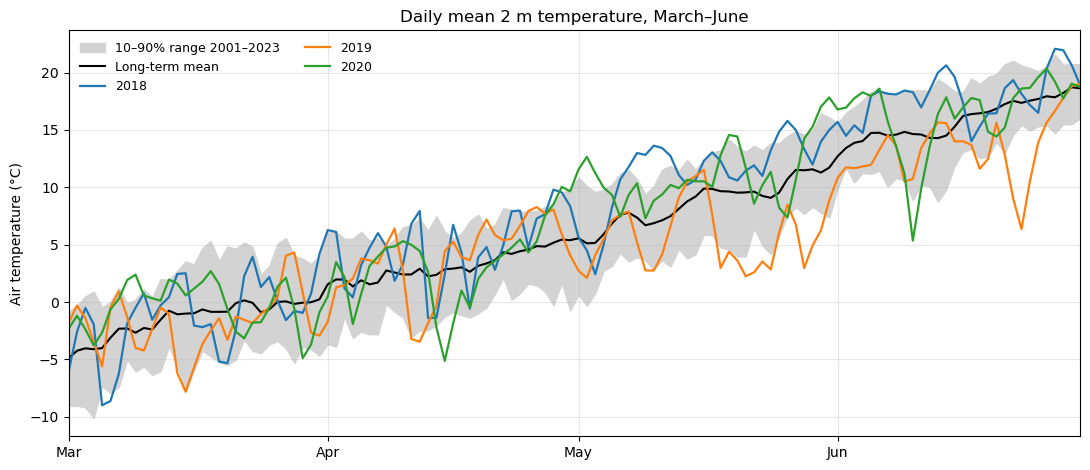

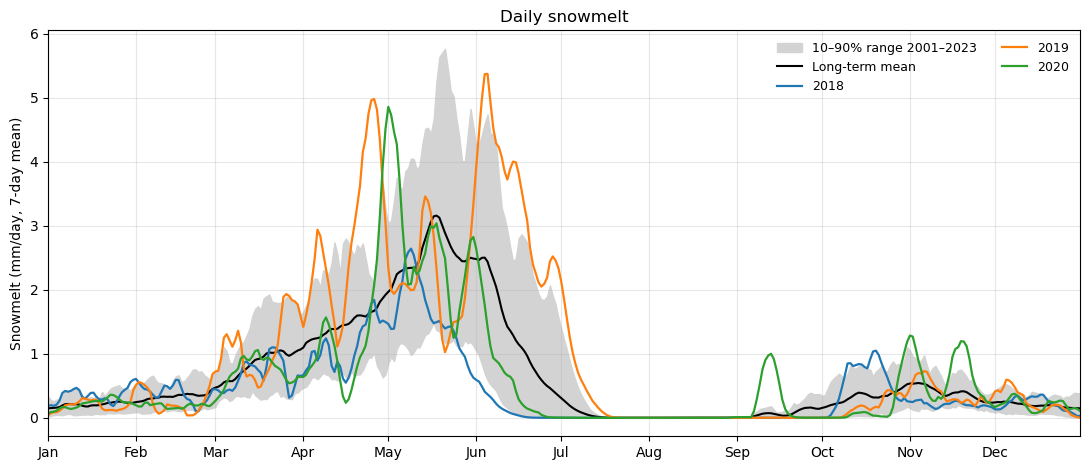

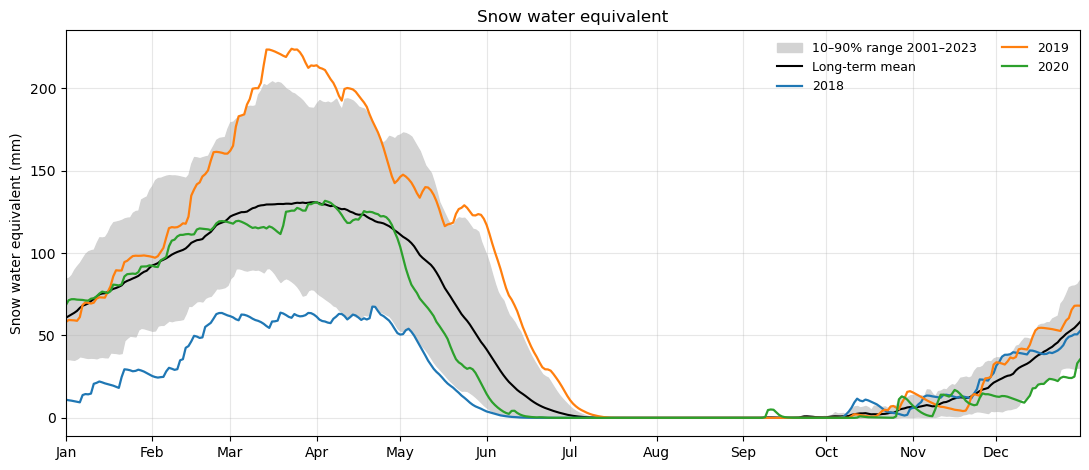

In [6]:
MONTH_TICKS = [pd.Timestamp(2021, m, 1).dayofyear for m in range(1, 13)]
MONTH_NAMES = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

def doy_plot(col, ylabel, title, fname, doy_range=(1, 365), smooth=1):
    d = daily[(daily["doy"] >= doy_range[0]) & (daily["doy"] <= doy_range[1])]
    pivot = d.pivot_table(index="doy", columns="year", values=col)
    if smooth > 1:
        pivot = pivot.rolling(smooth, center=True, min_periods=1).mean()
    fig, ax = plt.subplots(figsize=(11, 4.8))
    ax.fill_between(pivot.index, pivot.quantile(0.1, axis=1), pivot.quantile(0.9, axis=1),
                    color="lightgray", label=f"10–90% range {START_YEAR}–{END_YEAR}")
    ax.plot(pivot.index, pivot.mean(axis=1), color="k", lw=1.5, label="Long-term mean")
    for yr, color in zip(HIGHLIGHT_YEARS, YEAR_COLORS):
        if yr in pivot.columns:
            ax.plot(pivot.index, pivot[yr], color=color, lw=1.6, label=str(yr))
    ax.set_xticks([t for t in MONTH_TICKS if doy_range[0] <= t <= doy_range[1]])
    ax.set_xticklabels([n for t, n in zip(MONTH_TICKS, MONTH_NAMES) if doy_range[0] <= t <= doy_range[1]])
    ax.set(xlim=doy_range, ylabel=ylabel, title=title)
    ax.legend(frameon=False, fontsize=9, ncol=2); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(f"{FIG_DIR}/{fname}"); plt.show()

spring = (pd.Timestamp(2021, TEMP_MONTHS[0], 1).dayofyear,
          (pd.Timestamp(2021, TEMP_MONTHS[1], 1) + pd.offsets.MonthEnd(1)).dayofyear)
doy_plot("temp_c", "Air temperature (°C)", "Daily mean 2 m temperature, March–June", "02_temperature_doy.png", spring)
doy_plot("snowmelt_mm", "Snowmelt (mm/day, 7-day mean)", "Daily snowmelt", "03_snowmelt_doy.png", smooth=7)
doy_plot("swe_mm", "Snow water equivalent (mm)", "Snow water equivalent", "04_swe_doy.png")

## 6. Yearly snowmelt metrics

For each complete year: spring (March–June) mean temperature, total snowmelt, peak SWE and its date, and the
days of the year by which 25%, 50% and 75% of that year's snowmelt had occurred. The 50% date (**melt midpoint**)
is a standard measure of snowmelt timing: earlier dates mean an earlier spring melt.

In [7]:
def year_metrics(g):
    melt = g["snowmelt_mm"].clip(lower=0)
    cum = melt.cumsum().values
    total = cum[-1]
    frac_doy = lambda f: int(g["doy"].values[np.argmax(cum >= f * total)]) if total > 0 else np.nan
    spring_mask = g.index.month.isin(range(TEMP_MONTHS[0], TEMP_MONTHS[1] + 1))
    return pd.Series({
        "spring_temp_c": g.loc[spring_mask, "temp_c"].mean(),
        "total_snowmelt_mm": total,
        "total_snowfall_mm": g["snowfall_mm"].sum(),
        "total_precip_mm": g["precip_mm"].sum(),
        "peak_swe_mm": g["swe_mm"].max(),
        "peak_swe_doy": int(g["doy"].values[g["swe_mm"].values.argmax()]),
        "melt_25_doy": frac_doy(0.25),
        "melt_50_doy": frac_doy(0.50),
        "melt_75_doy": frac_doy(0.75),
    })

complete = daily.groupby("year").filter(lambda g: len(g) >= 365)
metrics = complete.groupby("year").apply(year_metrics)
metrics.round(2).to_csv(f"{OUT_DIR}/yearly_snowmelt_metrics.csv")

years = metrics.index.values
def trend(y):
    y = np.asarray(y, dtype=float); ok = np.isfinite(y)
    slope, intercept, lo, hi = stats.theilslopes(y[ok], years[ok])
    tau, p = stats.kendalltau(years[ok], y[ok])
    return slope, intercept, p

NAMES = {"spring_temp_c": "Spring temperature (°C)", "total_snowmelt_mm": "Total snowmelt (mm)",
         "peak_swe_mm": "Peak SWE (mm)", "peak_swe_doy": "Peak SWE date (day of year)",
         "melt_50_doy": "Melt midpoint (day of year)"}
trend_table = pd.DataFrame({
    NAMES[c]: {"Mean": metrics[c].mean(), "Std. dev.": metrics[c].std(),
               "Theil–Sen /decade": 10 * trend(metrics[c])[0], "Mann–Kendall p": trend(metrics[c])[2]}
    for c in NAMES}).T
r, p_r = stats.pearsonr(metrics["spring_temp_c"], metrics["melt_50_doy"])
sens = stats.theilslopes(metrics["melt_50_doy"], metrics["spring_temp_c"])[0]
print(f"Spring temperature vs melt midpoint: r = {r:.2f} (p = {p_r:.3f}); {sens:+.1f} days per °C")
trend_table.round(3).to_csv(f"{OUT_DIR}/snowmelt_trend_summary.csv")
display(trend_table.round(3))
metrics.loc[[y for y in HIGHLIGHT_YEARS if y in metrics.index]].round(1)

Spring temperature vs melt midpoint: r = -0.73 (p = 0.000); -5.9 days per °C


,Mean,Std. dev.,Theil–Sen /decade,Mann–Kendall p
Spring temperature (°C),6.542,1.139,0.188,0.676
Total snowmelt (mm),236.754,53.819,11.754,0.676
Peak SWE (mm),145.660,45.707,11.017,0.530
Peak SWE date (day of year),88.174,21.313,-3.182,0.491
Melt midpoint (day of year),131.609,11.191,0.000,0.916


,spring_temp_c,total_snowmelt_mm,total_snowfall_mm,total_precip_mm,peak_swe_mm,peak_swe_doy,melt_25_doy,melt_50_doy,melt_75_doy
year,,,,,,,,,
2018,8.1,159.4,246.1,481.3,67.5,111.0,85.0,124.0,145.0
2019,5.2,341.4,379.2,599.3,223.9,82.0,109.0,136.0,164.0
2020,7.7,215.2,223.5,369.6,131.7,94.0,113.0,131.0,153.0


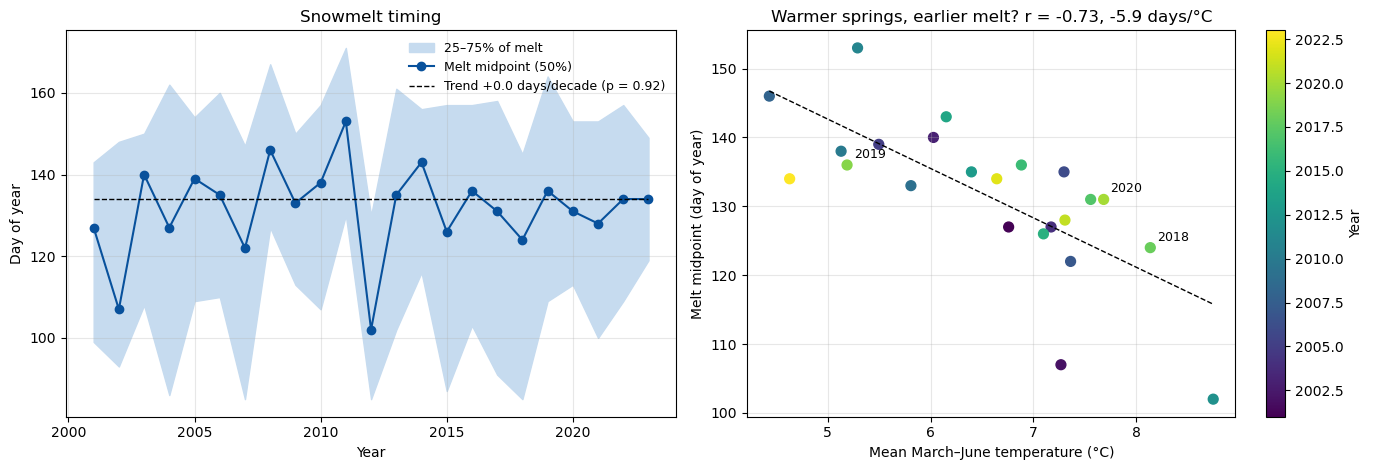

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ax = axes[0]
ax.fill_between(years, metrics["melt_25_doy"], metrics["melt_75_doy"], color="#c6dbef", label="25–75% of melt")
ax.plot(years, metrics["melt_50_doy"], "o-", color="#08519c", label="Melt midpoint (50%)")
slope, intercept, p = trend(metrics["melt_50_doy"])
ax.plot(years, intercept + slope * years, "k--", lw=1, label=f"Trend {10*slope:+.1f} days/decade (p = {p:.2f})")
ax.set(xlabel="Year", ylabel="Day of year", title="Snowmelt timing")
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.3)

ax = axes[1]
sc = ax.scatter(metrics["spring_temp_c"], metrics["melt_50_doy"], c=years, cmap="viridis", s=50)
xs = np.linspace(metrics["spring_temp_c"].min(), metrics["spring_temp_c"].max(), 50)
fit = np.polyfit(metrics["spring_temp_c"], metrics["melt_50_doy"], 1)
ax.plot(xs, np.polyval(fit, xs), "k--", lw=1)
for yr in HIGHLIGHT_YEARS:
    if yr in metrics.index:
        ax.annotate(str(yr), (metrics.loc[yr, "spring_temp_c"], metrics.loc[yr, "melt_50_doy"]),
                    textcoords="offset points", xytext=(5, 5), fontsize=9)
fig.colorbar(sc, ax=ax, label="Year")
ax.set(xlabel="Mean March–June temperature (°C)", ylabel="Melt midpoint (day of year)",
       title=f"Warmer springs, earlier melt? r = {r:.2f}, {sens:+.1f} days/°C")
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/05_melt_timing.png"); plt.show()

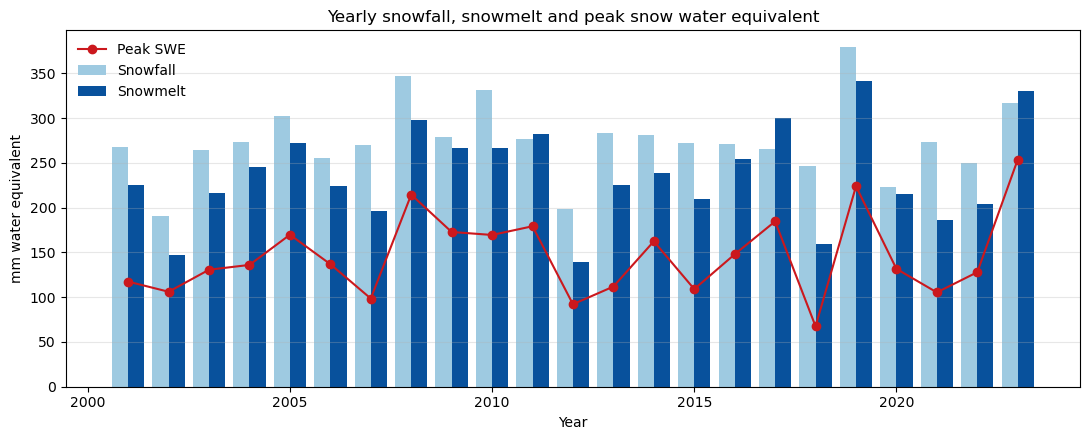

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
w = 0.4
ax.bar(years - w/2, metrics["total_snowfall_mm"], w, color="#9ecae1", label="Snowfall")
ax.bar(years + w/2, metrics["total_snowmelt_mm"], w, color="#08519c", label="Snowmelt")
ax.plot(years, metrics["peak_swe_mm"], "o-", color="#cb181d", label="Peak SWE")
ax.set(xlabel="Year", ylabel="mm water equivalent", title="Yearly snowfall, snowmelt and peak snow water equivalent")
ax.legend(frameon=False); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/06_snow_budget.png"); plt.show()

## 7. Notes

- **Data:** Muñoz Sabater, J. (2019). ERA5-Land daily aggregated data, Copernicus Climate Change Service;
  Lehner & Grill (2013), HydroSHEDS/HydroBASINS; NASA NASADEM elevation (background map only).
- Values are basin means at `SCALE` = 10 km. ERA5-Land is a model reanalysis at ~11 km, so it smooths
  mountain snowpacks; absolute SWE values can differ from SNOTEL station observations, while year-to-year
  differences and timing are usually more reliable.
- Years with very little snowmelt (low-snow basins) give unstable timing metrics; choose a basin with a seasonal snowpack.
- To study another basin, change `POINT` and set `FORCE_RECOMPUTE = True` once.